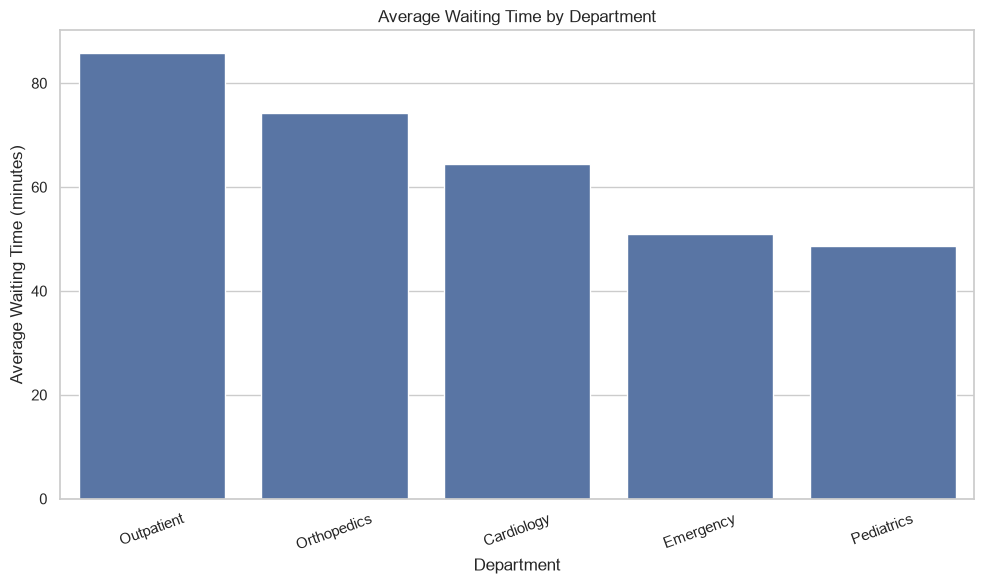

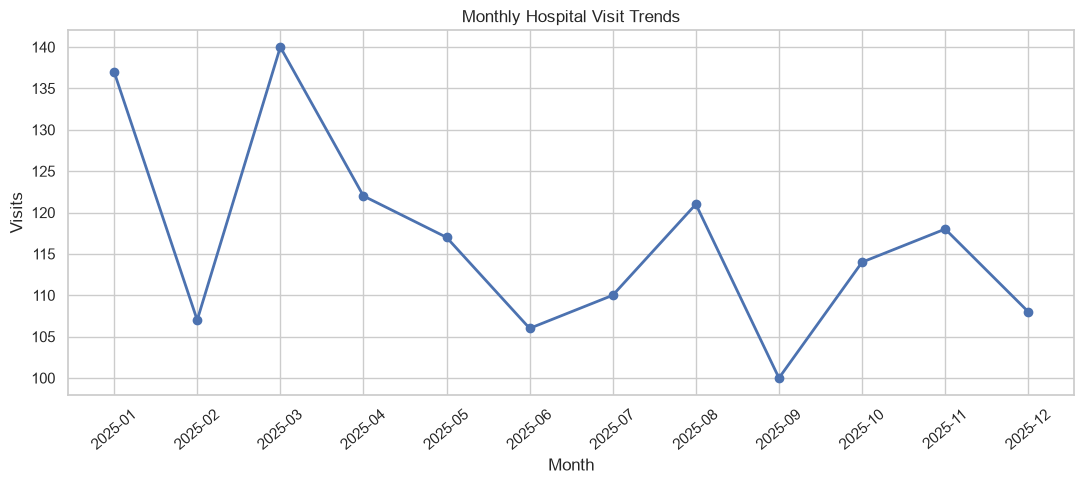

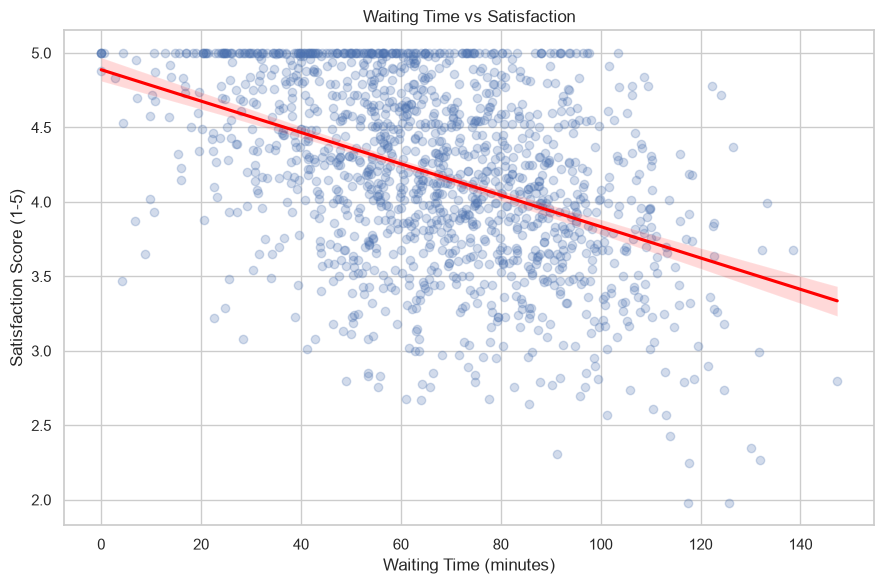

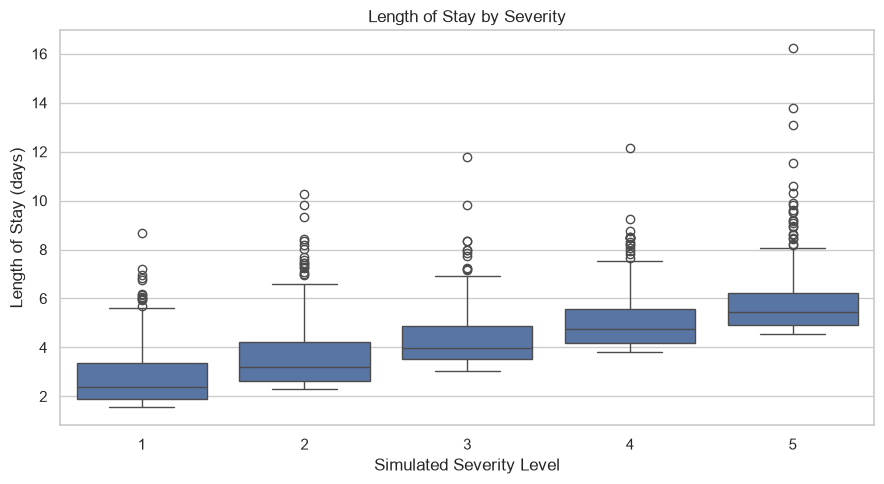

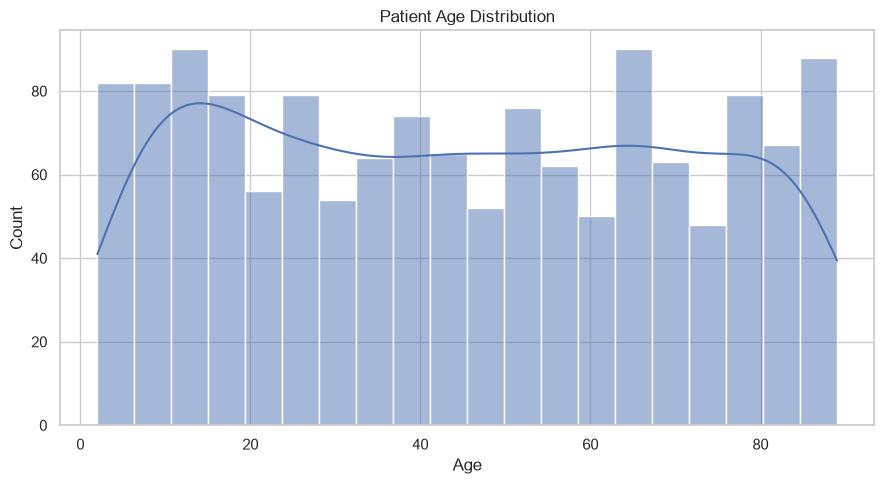


PROJECT 4 COMPLETED
Visits: 1400
Average Wait: 66.6
Average Stay: 4.38
Busiest Department: Outpatient
Hypothesis Test p-value: 6.608909363181975e-100
Charts: 5
PDF: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/healthcare-data-analysis/project4_healthcare_analysis/reports/healthcare_analysis_report.pdf
Saved in: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/healthcare-data-analysis/project4_healthcare_analysis


In [1]:

# ============================================================
# PROJECT 4: HEALTHCARE DATA ANALYSIS
# ONE-CELL COMPLETE PROJECT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
)
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from xml.sax.saxutils import escape

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(44)

# 1. PROJECT SETUP
base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
if base.name.startswith("project"):
    base = base.parent
if (base / "Data_Analysis_Portfolio").is_dir():
    base = base / "Data_Analysis_Portfolio"

project_name = "project4_healthcare_analysis"
root = base / project_name

for name in ["data", "notebooks", "reports",
             "visualizations", "docs", "src"]:
    (root / name).mkdir(parents=True, exist_ok=True)

plots = []

def save_chart(fig, filename):
    fig.tight_layout()
    path = root / "visualizations" / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plots.append(path)
    plt.show()
    plt.close(fig)

def create_report(title, sections, filename):
    styles = getSampleStyleSheet()
    story = [
        Paragraph(escape(title), styles["Title"]),
        Paragraph("Simulated Hospital Operations",
                  styles["Italic"]),
        Spacer(1, 15)
    ]

    for heading, paragraphs in sections.items():
        story.append(Paragraph(
            escape(heading), styles["Heading2"]
        ))
        for content in paragraphs:
            story.append(Paragraph(
                escape(str(content)), styles["BodyText"]
            ))
            story.append(Spacer(1, 8))

    for chart in plots:
        story.append(PageBreak())
        story.append(Paragraph(
            escape(chart.stem.replace("_", " ").title()),
            styles["Heading2"]
        ))
        img = Image(str(chart))
        scale = min(
            440 / img.drawWidth,
            620 / img.drawHeight
        )
        img.drawWidth *= scale
        img.drawHeight *= scale
        story.append(img)

    pdf = root / "reports" / filename
    SimpleDocTemplate(
        str(pdf), pagesize=A4, title=title
    ).build(story)
    return pdf

# 2. GENERATE SIMULATED HOSPITAL DATA
n = 1400

departments = [
    "Emergency",
    "Outpatient",
    "Cardiology",
    "Orthopedics",
    "Pediatrics"
]

department = rng.choice(
    departments, n,
    p=[0.25, 0.30, 0.16, 0.15, 0.14]
)

severity = rng.integers(1, 6, n)
age = rng.integers(2, 90, n)

base_wait = {
    "Emergency": 50,
    "Outpatient": 85,
    "Cardiology": 65,
    "Orthopedics": 75,
    "Pediatrics": 45
}

wait_minutes = np.clip(
    np.array([base_wait[d] for d in department])
    + rng.normal(0, 18, n)
    + (severity - 3) * 5,
    0, 300
)

length_of_stay = np.clip(
    0.8 + 0.75 * severity
    + rng.exponential(1.3, n),
    0.5, 20
)

satisfaction = np.clip(
    5 - wait_minutes / 85
    + rng.normal(0, 0.6, n),
    1, 5
)

hospital_dates = pd.date_range(
    "2025-01-01", "2025-12-31", freq="D"
)

df_raw = pd.DataFrame({
    "VisitID": [f"V{i:05d}" for i in range(1, n+1)],
    "Date": rng.choice(hospital_dates, n),
    "Department": department,
    "Age": age,
    "Severity": severity,
    "WaitMinutes": wait_minutes.round(2),
    "LengthOfStayDays": length_of_stay.round(2),
    "SatisfactionScore": satisfaction.round(2)
})

# Deliberately insert data-quality issues
df_raw.loc[0, "Age"] = 140
df_raw.loc[1, "WaitMinutes"] = -20
df_raw.loc[2, "SatisfactionScore"] = np.nan
df_raw.loc[3, "LengthOfStayDays"] = -4

df_raw = pd.concat(
    [df_raw, df_raw.iloc[[4]]],
    ignore_index=True
)

df_raw.to_csv(
    root / "data" / "hospital_raw.csv",
    index=False
)

# 3. DATA CLEANING
duplicates = df_raw["VisitID"].duplicated().sum()

df = df_raw.drop_duplicates("VisitID").copy()

df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce"
)

numeric_cols = [
    "Age", "Severity", "WaitMinutes",
    "LengthOfStayDays", "SatisfactionScore"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

validation_ranges = {
    "Age": (0, 110),
    "Severity": (1, 5),
    "WaitMinutes": (0, 720),
    "LengthOfStayDays": (0, 365),
    "SatisfactionScore": (1, 5)
}

for col, (minimum, maximum) in validation_ranges.items():
    df.loc[
        ~df[col].between(minimum, maximum),
        col
    ] = np.nan

    df[col] = df.groupby("Department")[col].transform(
        lambda x: x.fillna(x.median())
    )

df = df.dropna(subset=["Date", "Department"])

df["Age"] = df["Age"].round().astype(int)
df["Severity"] = df["Severity"].round().astype(int)

df["Month"] = df["Date"].dt.to_period(
    "M"
).astype(str)

assert df["VisitID"].is_unique
assert df[numeric_cols].notna().all().all()

for col, (minimum, maximum) in validation_ranges.items():
    assert df[col].between(minimum, maximum).all()

df.to_csv(
    root / "data" / "hospital_cleaned.csv",
    index=False
)

# 4. STATISTICAL ANALYSIS
average_wait = df["WaitMinutes"].mean()
median_wait = df["WaitMinutes"].median()
std_wait = df["WaitMinutes"].std()

average_stay = df["LengthOfStayDays"].mean()
average_satisfaction = df["SatisfactionScore"].mean()

wait_satisfaction_corr = df[
    "WaitMinutes"
].corr(df["SatisfactionScore"])

department_summary = df.groupby(
    "Department"
).agg(
    Visits=("VisitID", "count"),
    AverageWait=("WaitMinutes", "mean"),
    MedianWait=("WaitMinutes", "median"),
    AverageStay=("LengthOfStayDays", "mean"),
    AverageSatisfaction=("SatisfactionScore", "mean")
).sort_values("AverageWait", ascending=False)

monthly_summary = df.groupby(
    "Month", as_index=False
).agg(
    Visits=("VisitID", "count"),
    AverageWait=("WaitMinutes", "mean")
)

severity_summary = df.groupby(
    "Severity"
).agg(
    AverageStay=("LengthOfStayDays", "mean"),
    AverageWait=("WaitMinutes", "mean")
)

emergency_wait = df.loc[
    df["Department"] == "Emergency", "WaitMinutes"
]

outpatient_wait = df.loc[
    df["Department"] == "Outpatient", "WaitMinutes"
]

t_stat, p_value = stats.ttest_ind(
    emergency_wait,
    outpatient_wait,
    equal_var=False
)

department_summary.to_csv(
    root / "reports" / "department_statistics.csv"
)
monthly_summary.to_csv(
    root / "reports" / "monthly_statistics.csv",
    index=False
)
severity_summary.to_csv(
    root / "reports" / "severity_statistics.csv"
)

# 5. CHART 1: AVERAGE WAITING TIME
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=department_summary.index,
    y=department_summary["AverageWait"].values,
    ax=ax
)
ax.set_title("Average Waiting Time by Department")
ax.set_ylabel("Average Waiting Time (minutes)")
ax.tick_params(axis="x", rotation=20)
save_chart(fig, "01_department_waiting_times.png")

# 6. CHART 2: MONTHLY VISIT TRENDS
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    monthly_summary["Month"],
    monthly_summary["Visits"],
    marker="o",
    linewidth=2
)
ax.set_title("Monthly Hospital Visit Trends")
ax.set_xlabel("Month")
ax.set_ylabel("Visits")
ax.tick_params(axis="x", rotation=40)
save_chart(fig, "02_monthly_visits.png")

# 7. CHART 3: WAIT VS SATISFACTION
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(
    data=df,
    x="WaitMinutes",
    y="SatisfactionScore",
    scatter_kws={"alpha": 0.25},
    line_kws={"color": "red"},
    ax=ax
)
ax.set_title("Waiting Time vs Satisfaction")
ax.set_xlabel("Waiting Time (minutes)")
ax.set_ylabel("Satisfaction Score (1-5)")
save_chart(fig, "03_wait_vs_satisfaction.png")

# 8. CHART 4: SEVERITY VS LENGTH OF STAY
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Severity",
    y="LengthOfStayDays",
    ax=ax
)
ax.set_title("Length of Stay by Severity")
ax.set_xlabel("Simulated Severity Level")
ax.set_ylabel("Length of Stay (days)")
save_chart(fig, "04_severity_length_of_stay.png")

# 9. CHART 5: PATIENT AGE DISTRIBUTION
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    df["Age"],
    bins=20,
    kde=True,
    ax=ax
)
ax.set_title("Patient Age Distribution")
ax.set_xlabel("Age")
save_chart(fig, "05_age_distribution.png")

# 10. BUSINESS INSIGHTS
slowest_department = department_summary.index[0]
busiest_department = department_summary[
    "Visits"
].idxmax()

findings = [
    f"Total hospital visits: {len(df):,}.",
    f"Average waiting time: {average_wait:.2f} minutes.",
    f"Median waiting time: {median_wait:.2f} minutes.",
    f"Wait-time standard deviation: "
    f"{std_wait:.2f} minutes.",
    f"Average length of stay: "
    f"{average_stay:.2f} days.",
    f"Average satisfaction score: "
    f"{average_satisfaction:.2f}/5.",
    f"Highest mean waiting time: "
    f"{slowest_department}.",
    f"Highest visit volume: {busiest_department}.",
    f"Wait-satisfaction correlation: "
    f"{wait_satisfaction_corr:.3f}.",
    f"Emergency vs Outpatient Welch t-test "
    f"p-value: {p_value:.5g}."
]

recommendations = [
    f"Review simulated staffing and scheduling "
    f"requirements in {slowest_department}.",
    "Track waiting-time distributions rather than "
    "relying only on averages.",
    "Investigate operational reasons behind longer "
    "stays and department-level differences.",
    "Validate patient satisfaction patterns using "
    "real, ethically collected hospital data.",
    "Do not make clinical treatment decisions "
    "using this simulated dataset."
]

sections = {
    "Executive Summary": [
        f"The simulated dataset includes {len(df):,} "
        f"hospital visits across five departments. "
        f"Mean waiting time is {average_wait:.2f} "
        f"minutes."
    ],
    "Methodology": [
        "Data validation, department-median imputation, "
        "statistical aggregation, Pearson correlation, "
        "Welch t-test, and temporal analysis."
    ],
    "Data Quality": [
        f"Removed {duplicates} duplicated visit IDs.",
        "Invalid numerical values were replaced "
        "with department-level medians."
    ],
    "Key Findings": findings,
    "Operational Recommendations": recommendations,
    "Limitations": [
        "All hospital records are synthetic.",
        "No real patient information is included.",
        "Severity is an illustrative numerical measure.",
        "Wait-time relationships are not causal evidence.",
        "The findings must not guide real clinical care."
    ]
}

pdf = create_report(
    "Healthcare Operations Analysis",
    sections,
    "healthcare_analysis_report.pdf"
)

# 11. PROJECT DOCUMENTATION
readme = f"""# Healthcare Data Analysis

## Overview
Simulated hospital operations and patient-visit analysis.

## Dataset
- Visits: {len(df):,}
- Departments: {df['Department'].nunique()}
- Period: January-December 2025
- Source: Simulated

## Methods
Missing-value handling, duplicate checks, department
aggregation, Pearson correlation and Welch t-test.

## Results
- Average wait: {average_wait:.2f} minutes
- Average stay: {average_stay:.2f} days
- Wait-satisfaction correlation: {wait_satisfaction_corr:.3f}

## Reproduce
Install requirements and execute the notebook's single cell.

## Outputs
- data/hospital_raw.csv
- data/hospital_cleaned.csv
- reports/healthcare_analysis_report.pdf
- reports/statistical CSV summaries
- visualizations/ (five PNG charts)

## Limitations
Simulated data. No clinical recommendations.
"""

(root / "README.md").write_text(
    readme, encoding="utf-8"
)

(root / "requirements.txt").write_text(
    "pandas\nnumpy\nmatplotlib\nseaborn\nscipy\nreportlab\n",
    encoding="utf-8"
)

(root / "docs" / "methodology.md").write_text(
    "Synthetic hospital data for operational analytics. "
    "Invalid values were handled with department medians. "
    "Hypothesis testing is illustrative and non-causal.\n",
    encoding="utf-8"
)

print("\n" + "="*60)
print("PROJECT 4 COMPLETED")
print("="*60)
print("Visits:", len(df))
print("Average Wait:", round(average_wait, 2))
print("Average Stay:", round(average_stay, 2))
print("Busiest Department:", busiest_department)
print("Hypothesis Test p-value:", p_value)
print("Charts:", len(plots))
print("PDF:", pdf)
print("Saved in:", root)
